# Healthcare Data Analytics – Cleaned Data Inspection

## 1. Load and Validate Cleaned Dataset

In [6]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Locate the project folder
possible_roots = [Path.cwd(), Path.cwd().parent]

project_root = next(
    (p for p in possible_roots
     if (p / "data" / "processed" / "diabetic_data_cleaned.csv").exists()),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not find diabetic_data_cleaned.csv in data/processed"
    )

# Load the cleaned dataset
file_path = (
    project_root / "data" / "processed" /
    "diabetic_data_cleaned.csv"
)

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (101766, 53)


,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,total_prior_visits,medication_count,medication_change_flag,diabetes_medication_flag
0,2278392,8222157,Caucasian,Female,[0-10),6,25,1,1,Not Recorded,...,No,No,No,No,No,NO,0,0,0,0
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,Not Recorded,...,No,No,No,Ch,Yes,>30,0,0,1,1
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,Not Recorded,...,No,No,No,No,Yes,NO,3,0,0,1
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,Not Recorded,...,No,No,No,Ch,Yes,NO,0,0,1,1
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,Not Recorded,...,No,No,No,Ch,Yes,NO,0,0,1,1


## 2. Dataset Validation

In [7]:

# Check dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Check missing values
print("\nTotal missing values:", df.isna().sum().sum())

# Check completely duplicated records
print("Duplicate rows:", df.duplicated().sum())

# Check unique encounters and patients
print("Unique encounters:", df["encounter_id"].nunique())
print("Unique patients:", df["patient_nbr"].nunique())

# Check the new engineered features
engineered_features = [
    "total_prior_visits",
    "medication_count",
    "medication_change_flag",
    "diabetes_medication_flag"
]

display(df[engineered_features].describe())


Rows: 101766
Columns: 53

Total missing values: 0
Duplicate rows: 0
Unique encounters: 101766
Unique patients: 71518


,total_prior_visits,medication_count,medication_change_flag,diabetes_medication_flag
count,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.202759,0.141314,0.461952,0.770031
std,2.291781,0.356296,0.498553,0.420815
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,1.000000
50%,0.000000,0.000000,0.000000,1.000000
75%,2.000000,0.000000,1.000000,1.000000
max,80.000000,3.000000,1.000000,1.000000


## 3. Readmission Distribution

In [ ]:
# Count each readmission category
readmission_counts = df["readmitted"].value_counts()

display(readmission_counts)

# Calculate percentages
readmission_percentage = (
    df["readmitted"].value_counts(normalize=True) * 100
).round(2)

display(readmission_percentage)

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Readmission by percentage


readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64

In [12]:
print("Total columns:", len(df.columns))
display(pd.DataFrame({
    "Column_Name": df.columns,
    "Data_Type": df.dtypes.astype(str).values
}))

Total columns: 53


,Column_Name,Data_Type
0,encounter_id,int64
1,patient_nbr,int64
2,race,str
3,gender,str
4,age,str
5,admission_type_id,int64
6,discharge_disposition_id,int64
7,admission_source_id,int64
8,time_in_hospital,int64
9,payer_code,str


## 4. Exploratory Data Analysis

### 4.1 Patient Demographics

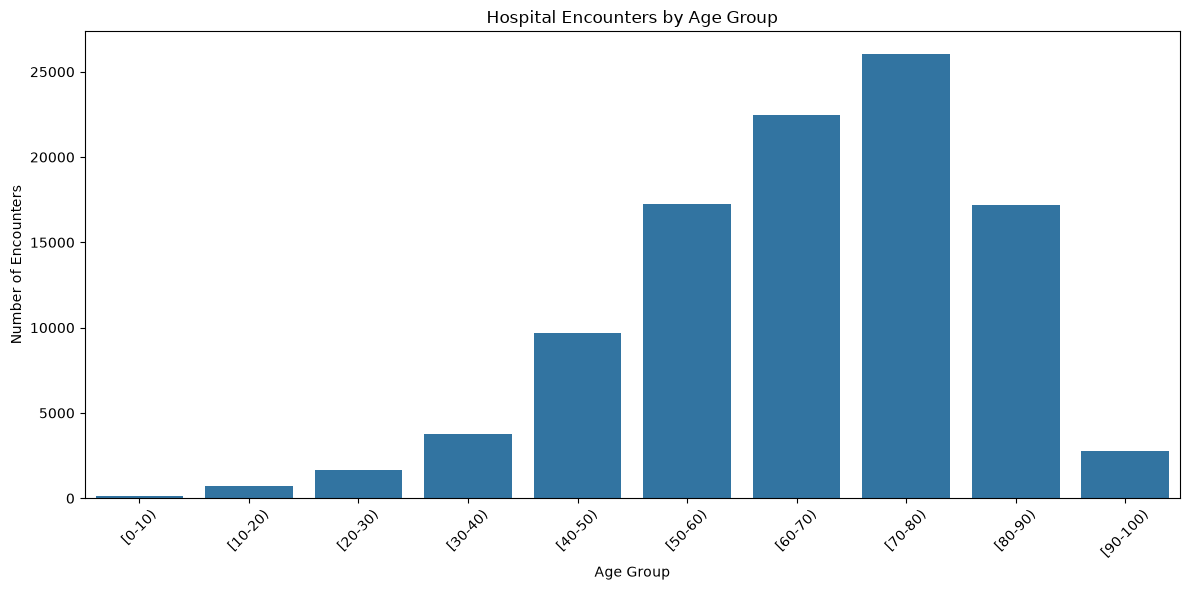

In [13]:
#A. Age distribution

age_order = [
    "[0-10)", "[10-20)", "[20-30)", "[30-40)",
    "[40-50)", "[50-60)", "[60-70)", "[70-80)",
    "[80-90)", "[90-100)"
]

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="age",
    order=age_order
)

plt.title("Hospital Encounters by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Encounters")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64


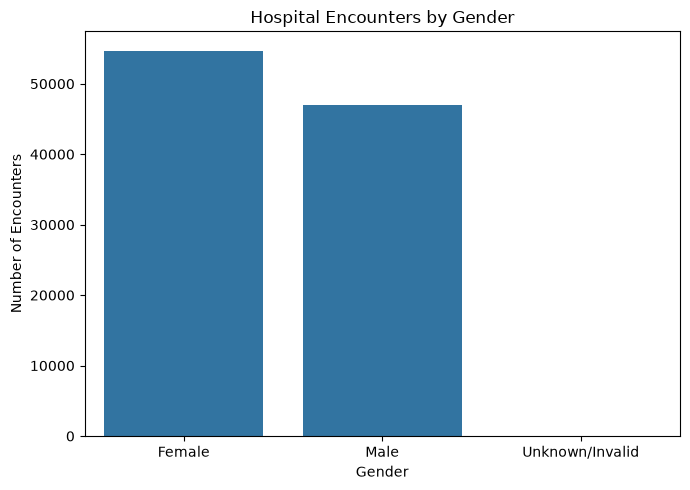

In [15]:
# B. Gender distribution
gender_counts = df["gender"].value_counts()
print(gender_counts)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=gender_counts.index,
    y=gender_counts.values
)

plt.title("Hospital Encounters by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()

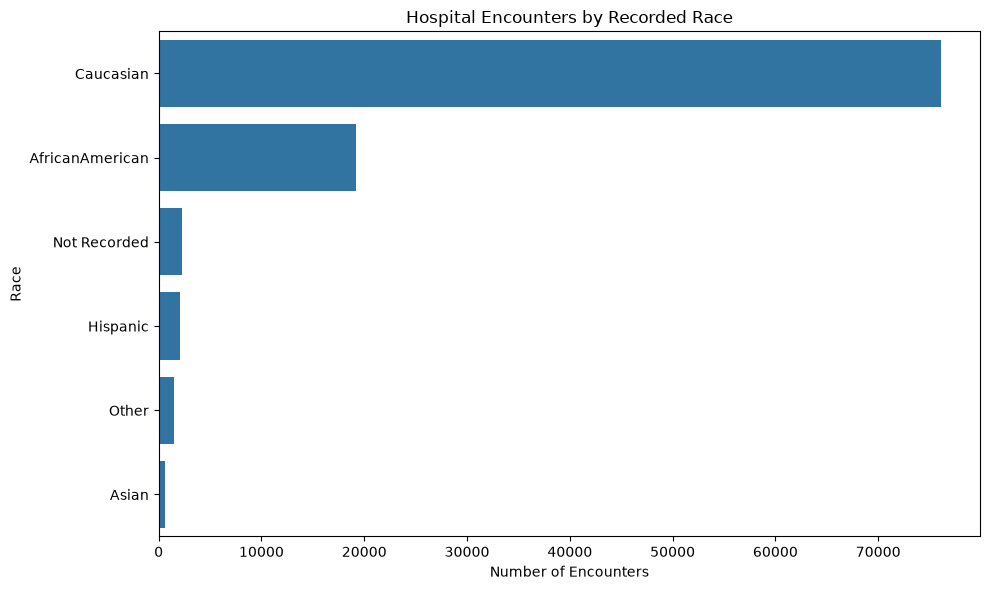

In [16]:
#C. Race distribution
race_counts = df["race"].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=race_counts.values,
    y=race_counts.index
)

plt.title("Hospital Encounters by Recorded Race")
plt.xlabel("Number of Encounters")
plt.ylabel("Race")
plt.tight_layout()
plt.show()

## 5. Hospital Activity Analysis

Hospital stay summary:


count    101766.000000
mean          4.395987
std           2.985108
min           1.000000
25%           2.000000
50%           4.000000
75%           6.000000
max          14.000000
Name: time_in_hospital, dtype: float64

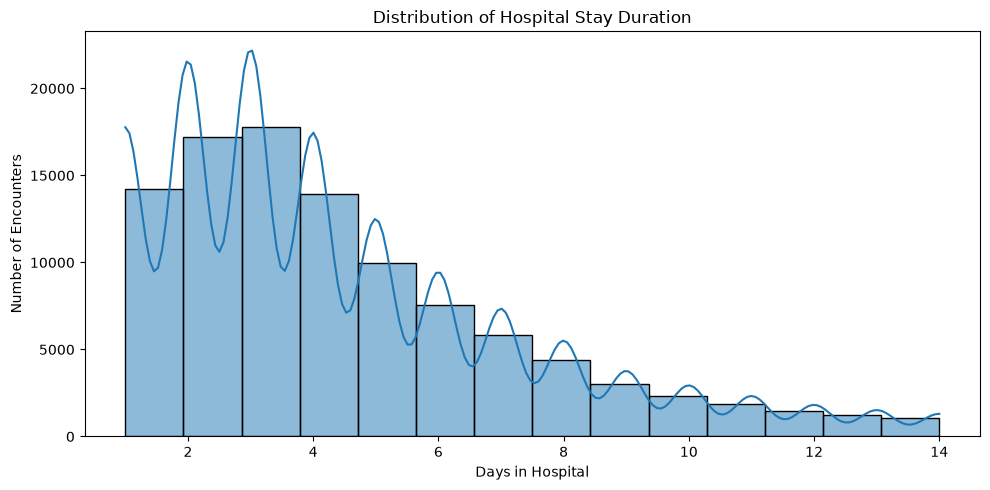

In [17]:
# 5.1 Length of hospital stay
# Convert to numeric
df["time_in_hospital"] = pd.to_numeric(
    df["time_in_hospital"], errors="coerce"
)

# Summary statistics
print("Hospital stay summary:")
display(df["time_in_hospital"].describe())

# Distribution chart
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="time_in_hospital",
    bins=14,
    kde=True
)

plt.title("Distribution of Hospital Stay Duration")
plt.xlabel("Days in Hospital")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()

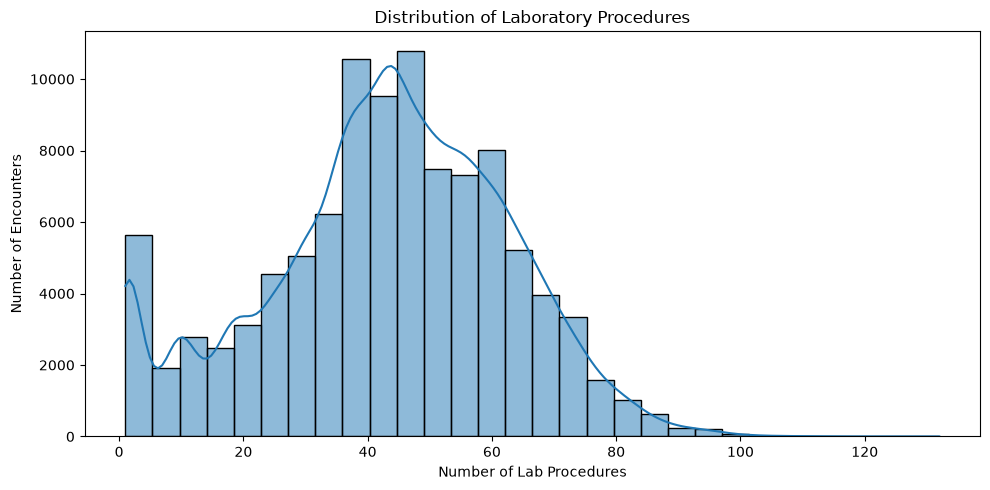

count    101766.000000
mean         43.095641
std          19.674362
min           1.000000
25%          31.000000
50%          44.000000
75%          57.000000
max         132.000000
Name: num_lab_procedures, dtype: float64

In [18]:
# 5.2 Number of laboratory procedures
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="num_lab_procedures",
    bins=30,
    kde=True
)

plt.title("Distribution of Laboratory Procedures")
plt.xlabel("Number of Lab Procedures")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()

display(df["num_lab_procedures"].describe())

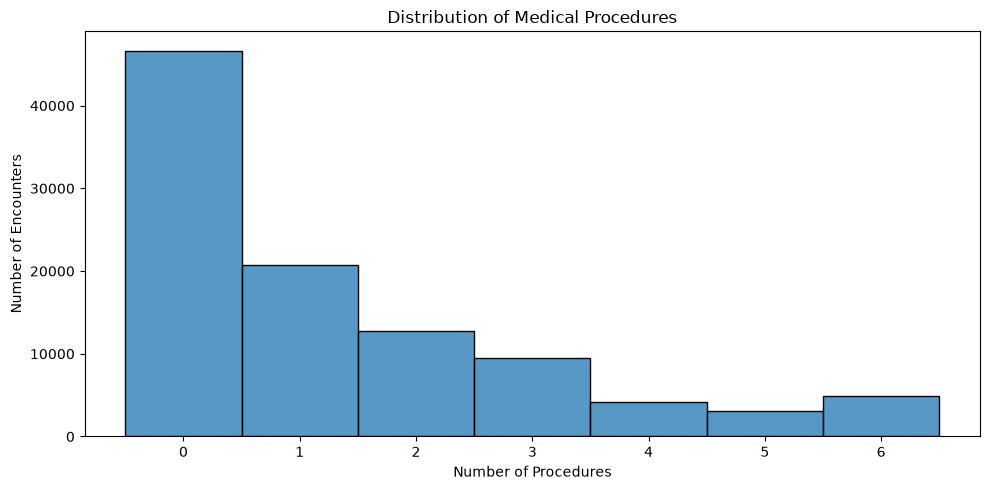

In [19]:
#5.3 Number of medical procedures
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="num_procedures",
    bins=15,
    discrete=True
)

plt.title("Distribution of Medical Procedures")
plt.xlabel("Number of Procedures")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()

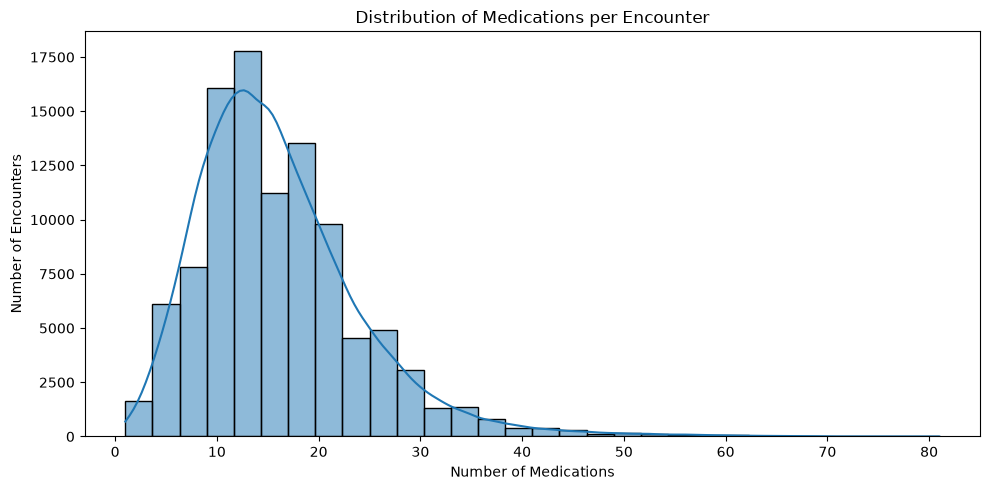

In [20]:
# 5.4 Number of medications
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="num_medications",
    bins=30,
    kde=True
)

plt.title("Distribution of Medications per Encounter")
plt.xlabel("Number of Medications")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()

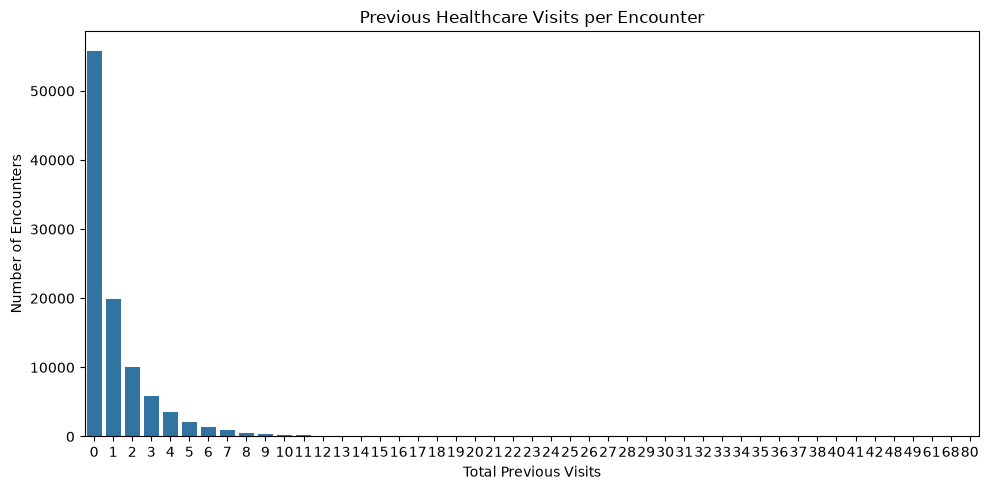

In [21]:
#5.5 Previous hospital visits
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="total_prior_visits"
)

plt.title("Previous Healthcare Visits per Encounter")
plt.xlabel("Total Previous Visits")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()

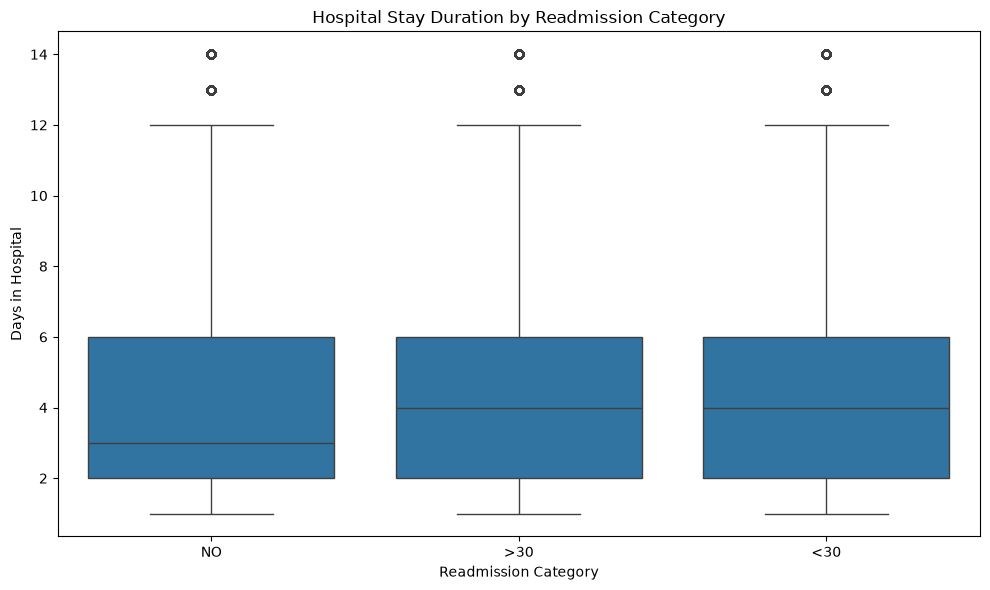

In [22]:
#5.6 Compare hospital stay with readmission
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="readmitted",
    y="time_in_hospital",
    order=["NO", ">30", "<30"]
)

plt.title("Hospital Stay Duration by Readmission Category")
plt.xlabel("Readmission Category")
plt.ylabel("Days in Hospital")
plt.tight_layout()
plt.show()